In [1]:
import numpy as np
import pandas as pd
import os
import torch
import adabmDCA as dca
import matplotlib.pyplot as plt
import seaborn as sns

tokens = dca.get_tokens("rna")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

### Generated sequences as validation and test

In [ ]:
# Training data (Natural sequences)
file_data = "../data/tRNA/RF00005.csv"
dot_bracket_structure = "(((((((..((((.......)))).(((((.......)))))....(((((.......))))))))))))." # RF00005
# file_data = "../data/SAM/SAM_all.csv"
# dot_bracket_structure = "((((((((....(((((...(((.....)))......)))))((((.((((((.......))))..))))))...(....((((((.....))))))..)))))))))" #RF00162

df_train = pd.read_csv(file_data)
# filter out sequences with non-standard tokens
df_train = df_train[df_train["sequence"].apply(lambda x: all(c in tokens for c in x))]
df_train = df_train.filter(items=["header", "sequence", "Tm"])
df_train.head()

,header,sequence,Tm
0,RRYP01036351.1/1-88,-------------AGAUGGAGGGAUAGACCCUGAGAAAUCUUAGCA...,100.0
1,JACAUA010000004.1/2903-2815,------------AAGGUGGAGGGACGGGCCCUGUGAAACCUUGGCA...,90.0
2,MTLA01000290.1/1-86,------------GAGGUGGAGGGACUGGCCCUUUGAAGCCUCAGCA...,80.0
3,MTLA01000562.1/1610-1514,---------AGAGAGGUGGAGGGACUGGCCCUAUGAAACCUCAGCA...,79.0
4,WQLB01000047.1/12050-12140,------UUCAGAGCGCCCGAGAGACUGGCUCGUUGACGGCGCGGCA...,84.0


In [15]:
# Test and validation data (Generated sequences)
file_gen = "../models/tRNA/bmDCA/gen.fasta"
file_tm_gen = "../models/tRNA/bmDCA/gen_tm.npy"
headers_gen, sequences_gen = dca.import_from_fasta(file_gen)
tms_gen = np.load(file_tm_gen)
df_gen = pd.DataFrame({"header": headers_gen, "sequence": sequences_gen, "Tm": tms_gen})
df_gen.head()

,header,sequence,Tm
0,sequence,GCCCCCGUCGUGAAACGAAGACACGGAGCACUCUUAAUGUUUCAUC...,89.0
1,sequence,GCC-CCGAAGUCUAACGGAAUGGCGCCGGCCUUGUAAACCGGU--U...,95.0
2,sequence,GGGGUUGUAGCUCAGUGGUAGAGCGCUUGCUUG-UAUGCGAGAGGC...,86.0
3,sequence,GGGGGGUUGGUAUAGUGGUAAGAUGCUAGUCUUUCACGCU-GUGAC...,103.0
4,sequence,GACAGCAUGAUUGAGUGGUAAGAUGAGAGCUUGGG--UCCUGU-AC...,78.0


In [16]:
from sklearn.model_selection import train_test_split
df_val, df_test = train_test_split(df_gen, test_size=0.5, random_state=42)

### Natural sequeces as validation and test

In [ ]:
# file_data = "../data/tRNA/RF00005.csv"
# dot_bracket_structure = "(((((((..((((.......)))).(((((.......)))))....(((((.......))))))))))))." # RF00005
file_data = "../data/SAM/SAM_all.csv"
dot_bracket_structure = "((((((((....(((((...(((.....)))......)))))((((.((((((.......))))..))))))...(....((((((.....))))))..)))))))))" #RF00162

df_all = pd.read_csv(file_data)
# filter out sequences with non-standard tokens
df_all = df_all[df_all["sequence"].apply(lambda x: all(c in tokens for c in x))]
df_all = df_all.filter(items=["header", "sequence", "Tm"])

from sklearn.model_selection import train_test_split
df_train, df_val_test = train_test_split(df_all, test_size=0.5, random_state=42)
df_val, df_test = train_test_split(df_val_test, test_size=0.5, random_state=42)

### Generated sequences as train, test and validation

In [2]:
# Test and validation data (Generated sequences)
file_gen = "../models/tRNA/bmDCA/gen.fasta"
file_tm_gen = "../models/tRNA/bmDCA/gen_tm.npy"
headers_gen, sequences_gen = dca.import_from_fasta(file_gen)
tms_gen = np.load(file_tm_gen)
df_gen = pd.DataFrame({"header": headers_gen, "sequence": sequences_gen, "Tm": tms_gen})
df_gen.head()

dot_bracket_structure = "(((((((..((((.......)))).(((((.......)))))....(((((.......))))))))))))." # RF00005
# dot_bracket_structure = "((((((((....(((((...(((.....)))......)))))((((.((((((.......))))..))))))...(....((((((.....))))))..)))))))))" #RF00162

from sklearn.model_selection import train_test_split
df_train, df_val_test = train_test_split(df_gen, test_size=0.5, random_state=42)
df_val, df_test = train_test_split(df_val_test, test_size=0.5, random_state=42)

### Dataloader and model

In [3]:
from torch.utils.data import Dataset, DataLoader
from torch import nn, optim

class DatasetRNA(Dataset):
    def __init__(self, df, tokens):
        self.df = df
        self.tokens = tokens
        self.sequences = df["sequence"].tolist()
        self.labels = df["Tm"].tolist()
        self.labels = torch.tensor(self.labels, dtype=torch.float32)
        self.L, self.q = len(self.sequences[0]), len(tokens)
        self.encoded_sequences = dca.encode_sequence(self.sequences, tokens)
        self.encoded_sequences = torch.tensor(self.encoded_sequences, dtype=torch.long)
        self.encoded_sequences = nn.functional.one_hot(self.encoded_sequences, num_classes=self.q).float()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        sequence = self.encoded_sequences[idx]
        label = self.labels[idx]
        return sequence, label

In [96]:
dataset_train = DatasetRNA(df_train, tokens)
dataset_val = DatasetRNA(df_val, tokens)
dataset_test = DatasetRNA(df_test, tokens)


In [97]:
batch_size = 64
dataloader_train = DataLoader(dataset_train, batch_size=batch_size, shuffle=True)
dataloader_val = DataLoader(dataset_val, batch_size=batch_size, shuffle=False)
dataloader_test = DataLoader(dataset_test, batch_size=batch_size, shuffle=False)

In [98]:
folder_model = "../models/tRNA/tm_predictor"
if not os.path.exists(folder_model):
    os.makedirs(folder_model)

In [58]:
# Define the neural network model. We start with a simple DNN with three hidden layers.
class DNN(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size, dropout=0.2):
        super(DNN, self).__init__()
        layers = []
        all_sizes = [input_size] + hidden_sizes + [output_size]
        for i in range(len(all_sizes) - 1):
            layers.append(nn.Linear(all_sizes[i], all_sizes[i+1]))
            if i < len(all_sizes) - 2:
                layers.append(nn.ReLU())
                layers.append(nn.Dropout(dropout))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)  # Flatten the input
        return self.network(x).squeeze()
    
# We use the L2 loss (MSELoss) for regression tasks.
input_size = dataset_train.L * dataset_train.q
hidden_sizes = [256, 128, 64]
output_size = 1
dropout = 0.1
learning_rate = 0.001
weight_decay = 1e-5

torch.set_float32_matmul_precision('high')
model = DNN(input_size, hidden_sizes, output_size, dropout).to(device)
model = torch.compile(model, mode='default')
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

In [86]:
# Define another model with convolutional layers
class CNN(nn.Module):
    def __init__(self, input_channels, output_size, dropout=0.2):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv1d(input_channels, 64, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(64, 128, kernel_size=3, padding=1)
        self.conv3 = nn.Conv1d(128, 256, kernel_size=3, padding=1)
        self.pool = nn.MaxPool1d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(256 * (dataset_train.L // 8), 128)  # Adjusted for pooling
        self.fc2 = nn.Linear(128, output_size)
        self.dropout = nn.Dropout(dropout)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.permute(0, 2, 1)  # Change to (batch, channels, length)
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)  # Flatten
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x.squeeze()
    
model = CNN(dataset_train.q, output_size, dropout).to(device)
model = torch.compile(model, mode='default')
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

In [87]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

### Training loop

In [88]:
# training loop
num_epochs = 50
train_losses = []
train_pearson_corr = []
val_losses = []
val_pearson_corr = []
best_val_loss = float('inf')
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    pearson_corr_epoch = []
    for sequences, labels in dataloader_train:
        sequences, labels = sequences.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(sequences)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * sequences.size(0)
        # compute pearson correlation
        preds = outputs.detach().cpu().numpy()
        targets = labels.detach().cpu().numpy()
        pearson_corr_epoch.append(np.corrcoef(preds, targets)[0, 1])
    epoch_train_loss = running_loss / len(dataloader_train.dataset)
    train_losses.append(epoch_train_loss)
    train_pearson_corr.append(np.mean(pearson_corr_epoch))

    model.eval()
    running_val_loss = 0.0
    pearson_corr_val_epoch = []
    with torch.no_grad():
        for sequences, labels in dataloader_val:
            sequences, labels = sequences.to(device), labels.to(device)
            outputs = model(sequences)
            loss = criterion(outputs, labels)
            running_val_loss += loss.item() * sequences.size(0)
            preds = outputs.detach().cpu().numpy()
            targets = labels.detach().cpu().numpy()
            pearson_corr_val_epoch.append(np.corrcoef(preds, targets)[0, 1])
    epoch_val_loss = running_val_loss / len(dataloader_val.dataset)
    val_losses.append(epoch_val_loss)
    val_pearson_corr.append(np.mean(pearson_corr_val_epoch))

    scheduler.step(epoch_val_loss)

    print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {epoch_train_loss:.4f}, Val Loss: {epoch_val_loss:.4f}')

    # Early stopping
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        counter = 0
        torch.save(model.state_dict(), os.path.join(folder_model, 'best_model.pth'))
    else:
        counter += 1
        if counter >= 10:
            print("Early stopping")
            break

Epoch [1/50], Train Loss: 294.3169, Val Loss: 132.4838
Epoch [2/50], Train Loss: 74.8393, Val Loss: 139.0056
Epoch [3/50], Train Loss: 72.8155, Val Loss: 128.1298
Epoch [4/50], Train Loss: 72.2825, Val Loss: 131.9197
Epoch [5/50], Train Loss: 69.0707, Val Loss: 128.7864
Epoch [6/50], Train Loss: 66.5554, Val Loss: 143.8136
Epoch [7/50], Train Loss: 65.9612, Val Loss: 128.6975
Epoch [8/50], Train Loss: 64.6513, Val Loss: 143.6935
Epoch [9/50], Train Loss: 64.2153, Val Loss: 126.4891
Epoch [10/50], Train Loss: 61.7488, Val Loss: 135.9251
Epoch [11/50], Train Loss: 60.6714, Val Loss: 132.2513
Epoch [12/50], Train Loss: 60.0592, Val Loss: 129.6314
Epoch [13/50], Train Loss: 60.3926, Val Loss: 153.6081
Epoch [14/50], Train Loss: 59.1458, Val Loss: 131.1455
Epoch [15/50], Train Loss: 59.3647, Val Loss: 134.1322
Epoch [16/50], Train Loss: 54.9618, Val Loss: 133.5640
Epoch [17/50], Train Loss: 54.6512, Val Loss: 128.3540
Epoch [18/50], Train Loss: 54.6078, Val Loss: 130.3698
Epoch [19/50], Tra

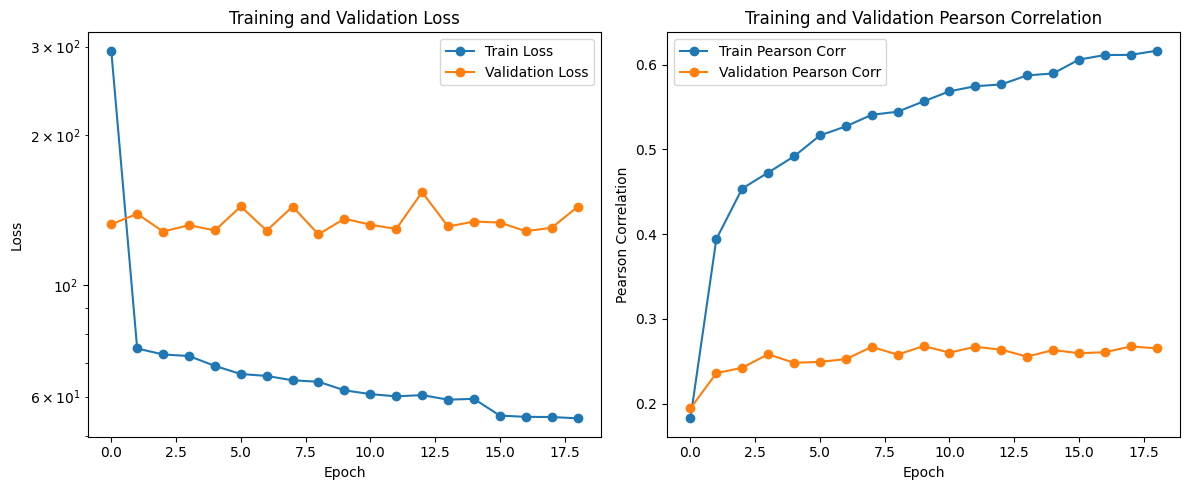

In [89]:
# print training and validation loss
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, "-o", label='Train Loss')
plt.plot(val_losses, "-o", label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.yscale('log')
plt.title('Training and Validation Loss')

plt.subplot(1, 2, 2)
plt.plot(train_pearson_corr, "-o", label='Train Pearson Corr')
plt.plot(val_pearson_corr, "-o", label='Validation Pearson Corr')
plt.xlabel('Epoch')
plt.ylabel('Pearson Correlation')
plt.legend()
plt.title('Training and Validation Pearson Correlation')
plt.tight_layout()
plt.show()

In [74]:
# test the model on the test set
model.load_state_dict(torch.load(os.path.join(folder_model, 'best_model.pth')))
model.eval()
test_loss = 0.0
pearson_corr_test = []
with torch.no_grad():
    for sequences, labels in dataloader_test:
        sequences, labels = sequences.to(device), labels.to(device)
        outputs = model(sequences)
        loss = criterion(outputs, labels)
        test_loss += loss.item() * sequences.size(0)
        preds = outputs.detach().cpu().numpy()
        targets = labels.detach().cpu().numpy()
        pearson_corr_test.append(np.corrcoef(preds, targets)[0, 1])
test_pearson_corr = np.mean(pearson_corr_test)
print(f'Test Pearson Correlation: {test_pearson_corr:.4f}')
test_loss /= len(dataloader_test.dataset)
print(f'Test Loss: {test_loss:.4f}')

Test Pearson Correlation: 0.6788
Test Loss: 41.2570


## CNN with secondary structure

In [3]:
from torch.utils.data import Dataset, DataLoader
from torch import nn, optim

# Dataset that also uses the secondary structure to produce a pairing matrix identifying the G-C and c-G pairs
class DatasetRNAWithStructure(Dataset):
    def __init__(self, df, tokens, dot_bracket_structure):
        self.df = df
        self.tokens = tokens
        self.dot_bracket_structure = dot_bracket_structure
        self.sequences = df["sequence"].tolist()
        self.labels = df["Tm"].tolist()
        self.labels = torch.tensor(self.labels, dtype=torch.float32)
        self.L, self.q = len(self.sequences[0]), len(tokens)
        self.encoded_sequences = dca.encode_sequence(self.sequences, tokens)
        self.encoded_sequences = torch.tensor(self.encoded_sequences, dtype=torch.long)
        self.encoded_sequences = nn.functional.one_hot(self.encoded_sequences, num_classes=self.q).float()
        
        # extract pairs from the dot-bracket notation
        stack = []
        pairs = []
        for i, char in enumerate(dot_bracket_structure):
            if char == '(':
                stack.append(i)
            elif char == ')':
                if stack:
                    j = stack.pop()
                    pairs.append((j, i))
        self.pairs = pairs

    def create_pairing_matrix(self, x: str):
        pairing_matrix = np.zeros((self.L, self.L), dtype=np.float32)
        for i, j in self.pairs:
            if (x[i] == 'G' and x[j] == 'C') or (x[i] == 'C' and x[j] == 'G'):
                pairing_matrix[i, j] = 1.0
                pairing_matrix[j, i] = 1.0
        return torch.tensor(pairing_matrix, dtype=torch.float32)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        sequence = self.encoded_sequences[idx]
        label = self.labels[idx]
        pairing_matrix = self.create_pairing_matrix(self.sequences[idx])
        return sequence, label, pairing_matrix

In [4]:
dataset_train = DatasetRNAWithStructure(df_train, tokens, dot_bracket_structure)
dataset_val = DatasetRNAWithStructure(df_val, tokens, dot_bracket_structure)
dataset_test = DatasetRNAWithStructure(df_test, tokens, dot_bracket_structure)

In [5]:
batch_size = 64
dataloader_train = DataLoader(dataset_train, batch_size=batch_size, shuffle=True)
dataloader_val = DataLoader(dataset_val, batch_size=batch_size, shuffle=False)
dataloader_test = DataLoader(dataset_test, batch_size=batch_size, shuffle=False)

In [6]:
folder_model = "../models/tRNA/tm_predictor"
if not os.path.exists(folder_model):
    os.makedirs(folder_model)

In [15]:
# Define a CNN model that processes the pairing matrix with Conv2D, then combines with sequence features
class CNNWithStructure(nn.Module):
    def __init__(self, input_channels, output_size, dropout=0.2):
        super(CNNWithStructure, self).__init__()
        # Sequence branch (Conv1D)
        self.seq_conv1 = nn.Conv1d(input_channels, 64, kernel_size=3, padding=1)
        self.seq_conv2 = nn.Conv1d(64, 128, kernel_size=3, padding=1)
        self.seq_conv3 = nn.Conv1d(128, 256, kernel_size=3, padding=1)
        self.seq_pool = nn.MaxPool1d(kernel_size=2, stride=2)

        # Pairing matrix branch (Conv2D)
        self.pair_conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.pair_conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pair_conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pair_pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Calculate flattened sizes
        seq_flatten_size = 256 * (dataset_train.L // 8)
        pair_flatten_size = 64 * (dataset_train.L // 8) * (dataset_train.L // 8)

        # Fully connected layers
        self.fc1 = nn.Linear(seq_flatten_size + pair_flatten_size, 128)
        self.fc2 = nn.Linear(128, output_size)
        self.dropout = nn.Dropout(dropout)
        self.relu = nn.ReLU()

    def forward(self, x, pairing_matrix):
        # Sequence branch
        x_seq = x.permute(0, 2, 1)  # (batch, channels, length)
        x_seq = self.seq_pool(self.relu(self.seq_conv1(x_seq)))
        x_seq = self.seq_pool(self.relu(self.seq_conv2(x_seq)))
        x_seq = self.seq_pool(self.relu(self.seq_conv3(x_seq)))
        x_seq = x_seq.view(x_seq.size(0), -1)

        # Pairing matrix branch
        x_pair = pairing_matrix.unsqueeze(1)  # (batch, 1, L, L)
        x_pair = self.pair_pool(self.relu(self.pair_conv1(x_pair)))
        x_pair = self.pair_pool(self.relu(self.pair_conv2(x_pair)))
        x_pair = self.pair_pool(self.relu(self.pair_conv3(x_pair)))
        x_pair = x_pair.view(x_pair.size(0), -1)

        # Combine
        x_combined = torch.cat([x_seq, x_pair], dim=1)
        x_combined = self.dropout(self.relu(self.fc1(x_combined)))
        x_combined = self.fc2(x_combined)
        return x_combined.squeeze()
    
# We use the L2 loss (MSELoss) for regression tasks
output_size = 1
dropout = 0.2
learning_rate = 0.0005
weight_decay = 1e-5

torch.set_float32_matmul_precision('high')
model = CNNWithStructure(dataset_train.q, output_size, dropout).to(device)
model = torch.compile(model, mode='default')
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

In [16]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

### Training loop

In [17]:
# training loop
num_epochs = 200
train_losses = []
train_pearson_corr = []
val_losses = []
val_pearson_corr = []
best_val_loss = float('inf')
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    pearson_corr_epoch = []
    for sequences, labels, pair_matrices in dataloader_train:
        sequences, labels, pair_matrices = sequences.to(device), labels.to(device), pair_matrices.to(device)
        optimizer.zero_grad()
        outputs = model(sequences, pair_matrices)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * sequences.size(0)
        # compute pearson correlation
        preds = outputs.detach().cpu().numpy()
        targets = labels.detach().cpu().numpy()
        pearson_corr_epoch.append(np.corrcoef(preds, targets)[0, 1])
    epoch_train_loss = running_loss / len(dataloader_train.dataset)
    train_losses.append(epoch_train_loss)
    train_pearson_corr.append(np.mean(pearson_corr_epoch))

    model.eval()
    running_val_loss = 0.0
    pearson_corr_val_epoch = []
    with torch.no_grad():
        for sequences, labels, pair_matrices in dataloader_val:
            sequences, labels, pair_matrices = sequences.to(device), labels.to(device), pair_matrices.to(device)
            outputs = model(sequences, pair_matrices)
            loss = criterion(outputs, labels)
            running_val_loss += loss.item() * sequences.size(0)
            preds = outputs.detach().cpu().numpy()
            targets = labels.detach().cpu().numpy()
            pearson_corr_val_epoch.append(np.corrcoef(preds, targets)[0, 1])
    epoch_val_loss = running_val_loss / len(dataloader_val.dataset)
    val_losses.append(epoch_val_loss)
    val_pearson_corr.append(np.mean(pearson_corr_val_epoch))

    scheduler.step(epoch_val_loss)

    print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {epoch_train_loss:.4f}, Val Loss: {epoch_val_loss:.4f}')

    # Early stopping
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        counter = 0
        torch.save(model.state_dict(), os.path.join(folder_model, 'best_model.pth'))
    else:
        counter += 1
        if counter >= 20:
            print("Early stopping")
            break

Epoch [1/200], Train Loss: 1553.5699, Val Loss: 135.5676
Epoch [2/200], Train Loss: 174.2721, Val Loss: 134.2363
Epoch [3/200], Train Loss: 167.8463, Val Loss: 134.0567
Epoch [4/200], Train Loss: 165.7736, Val Loss: 137.9417
Epoch [5/200], Train Loss: 166.0824, Val Loss: 130.5333
Epoch [6/200], Train Loss: 162.4197, Val Loss: 138.0180
Epoch [7/200], Train Loss: 165.9630, Val Loss: 129.0059
Epoch [8/200], Train Loss: 158.6539, Val Loss: 128.3982
Epoch [9/200], Train Loss: 158.5320, Val Loss: 126.2463
Epoch [10/200], Train Loss: 161.1341, Val Loss: 134.3619
Epoch [11/200], Train Loss: 158.3129, Val Loss: 125.9070
Epoch [12/200], Train Loss: 159.9198, Val Loss: 124.6963
Epoch [13/200], Train Loss: 153.2772, Val Loss: 142.0050
Epoch [14/200], Train Loss: 156.3393, Val Loss: 126.9102
Epoch [15/200], Train Loss: 157.7400, Val Loss: 126.6636
Epoch [16/200], Train Loss: 150.6705, Val Loss: 129.4646
Epoch [17/200], Train Loss: 156.8929, Val Loss: 136.6701
Epoch [18/200], Train Loss: 154.8672, V

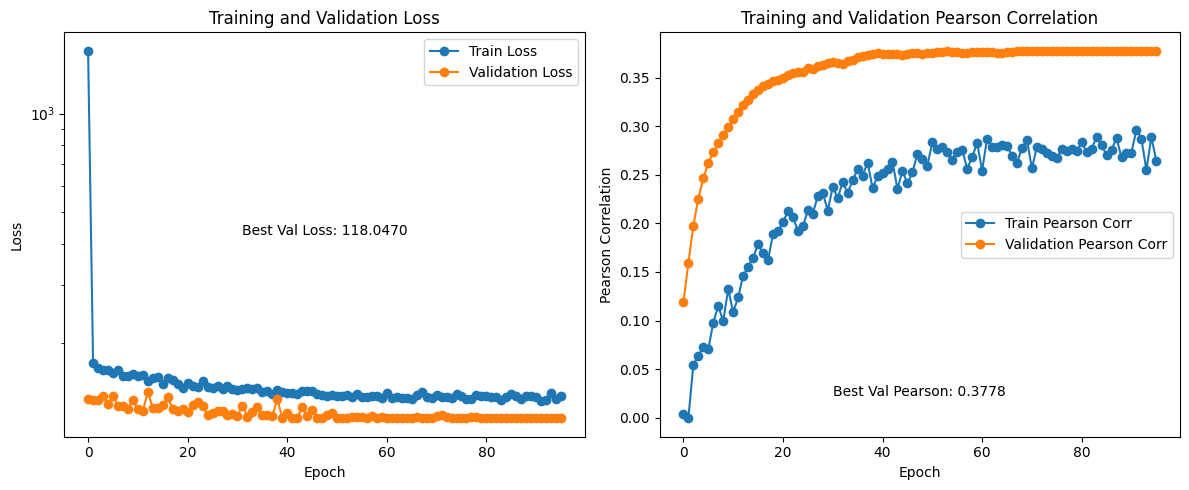

In [18]:
# print training and validation loss
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, "-o", label='Train Loss')
plt.plot(val_losses, "-o", label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.yscale('log')
plt.title('Training and Validation Loss')
plt.annotate(f"Best Val Loss: {min(val_losses):.4f}", xy=(0.5, 0.5), xycoords='axes fraction', ha='center')

plt.subplot(1, 2, 2)
plt.plot(train_pearson_corr, "-o", label='Train Pearson Corr')
plt.plot(val_pearson_corr, "-o", label='Validation Pearson Corr')
plt.xlabel('Epoch')
plt.ylabel('Pearson Correlation')
plt.legend()
plt.title('Training and Validation Pearson Correlation')
plt.annotate(f"Best Val Pearson: {max(val_pearson_corr):.4f}", xy=(0.5, 0.1), xycoords='axes fraction', ha='center')
plt.tight_layout()
plt.show()

In [19]:
# test the model on the test set
model.load_state_dict(torch.load(os.path.join(folder_model, 'best_model.pth')))
model.eval()
test_loss = 0.0
all_test_preds = []
all_test_targets = []
with torch.no_grad():
    for sequences, labels, pair_matrices in dataloader_test:
        sequences, labels, pair_matrices = sequences.to(device), labels.to(device), pair_matrices.to(device)
        outputs = model(sequences, pair_matrices)
        loss = criterion(outputs, labels)
        test_loss += loss.item() * sequences.size(0)
        all_test_preds.extend(outputs.detach().cpu().numpy())
        all_test_targets.extend(labels.detach().cpu().numpy())
all_test_preds = np.array(all_test_preds)
all_test_targets = np.array(all_test_targets)
test_pearson_corr = np.corrcoef(all_test_preds, all_test_targets)[0, 1]
print(f'Test Pearson Correlation: {test_pearson_corr:.4f}')
test_loss /= len(dataloader_test.dataset)
print(f'Test Loss: {test_loss:.4f}')

Test Pearson Correlation: 0.3794
Test Loss: 112.0006
